# EcoType — Forest Cover Type Classification
## Complete project workflow aligned with the GUVI/HCL project guide

**Project objective:** Predict one of the seven `Cover_Type` classes using the 12 cartographic input features.

This notebook follows the project guide's required sequence:
1. Data collection and understanding
2. Data cleaning, missing values, outlier investigation and skewness treatment
3. Feature engineering and categorical encoding
4. EDA and feature importance
5. Class imbalance handling
6. Feature selection
7. Five required classification algorithms
8. Model comparison and hyperparameter tuning
9. Final evaluation and saving the best model as `.pkl`
10. Streamlit deployment preparation

### Important methodology
- The final test set is held out and is not used to fit transformations, resampling, feature selection or hyperparameter tuning.
- IQR outliers are investigated, not automatically deleted. Valid terrain extremes are meaningful observations.
- Outlier capping is an experiment fitted on training data only. Compare it with the unmodified data before choosing it.
- Resampling is performed only inside training folds or on the training split, never on the test set.
- Macro F1 is reported alongside accuracy because the target is imbalanced.
- No accuracy level or prediction correctness is guaranteed in advance.


## 0. Install dependencies
Run only if a required package is missing. XGBoost is explicitly required by the GUVI/HCL guide.

In [1]:
# Uncomment if required:
# %pip install -U pandas numpy matplotlib seaborn scikit-learn imbalanced-learn xgboost joblib

import warnings
warnings.filterwarnings("ignore")

import time
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.inspection import permutation_importance
from imblearn.over_sampling import RandomOverSampler, SMOTENC
from imblearn.pipeline import Pipeline as ImbPipeline

try:
    from xgboost import XGBClassifier
    XGBOOST_AVAILABLE = True
except ImportError:
    XGBOOST_AVAILABLE = False
    print("XGBoost is not installed. Install it before running the five-model comparison.")

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)
print("Imports completed.")


Imports completed.


## 1. Data collection — load the dataset
Update `DATA_PATH` to the actual CSV path. The guide specifies 1,45,891 rows and 13 columns; your downloaded dataset may differ slightly, so verify the actual shape rather than forcing it.

In [2]:
DATA_PATH = Path("C:/Users/Gokul/OneDrive/Desktop/EcoType_Forest_Cover/data/cover_type.csv") if Path("data/cover_type.csv").exists() else Path("../data/cover_type.csv")
# Example Windows path:
# DATA_PATH = Path(r"C:\Users\YourName\OneDrive\Desktop\EcoType_Forest_Cover\data\cover_type.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH}. Update DATA_PATH.")

df = pd.read_csv(DATA_PATH)
print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (145890, 13)


,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,Cover_Type,Wilderness_Area,Soil_Type
0,2596,51,3,258,0,510,221,232,148,6279,Aspen,1,29
1,2590,56,2,212,-6,390,220,235,151,6225,Aspen,1,29
2,2804,139,9,268,65,3180,234,238,135,6121,Lodgepole Pine,1,12
3,2785,155,18,242,118,3090,238,238,122,6211,Lodgepole Pine,1,30
4,2595,45,2,153,-1,391,220,234,150,6172,Aspen,1,29


## 2. Data understanding — structure, types and target
The dataset should contain 12 input features and the target `Cover_Type`.

In [3]:
TARGET = "Cover_Type"
FEATURES = [
    "Elevation", "Aspect", "Slope",
    "Horizontal_Distance_To_Hydrology",
    "Vertical_Distance_To_Hydrology",
    "Horizontal_Distance_To_Roadways",
    "Hillshade_9am", "Hillshade_Noon", "Hillshade_3pm",
    "Horizontal_Distance_To_Fire_Points",
    "Wilderness_Area", "Soil_Type"
]

missing_columns = [c for c in FEATURES + [TARGET] if c not in df.columns]
if missing_columns:
    raise ValueError(f"Required dataset columns are missing: {missing_columns}")

print("Rows and columns:", df.shape)
print("\\nDataset information:")
df.info()
print("\\nDescriptive statistics:")
display(df.describe(include="all").T)
print("\\nMissing values:")
display(df.isna().sum().to_frame("Missing_Count"))
print("\\nDuplicate rows:", df.duplicated().sum())
print("\\nTarget class counts:")
display(df[TARGET].value_counts().sort_index().to_frame("Count"))


Rows and columns: (145890, 13)
\nDataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 145890 entries, 0 to 145889
Data columns (total 13 columns):
 #   Column                              Non-Null Count   Dtype 
---  ------                              --------------   ----- 
 0   Elevation                           145890 non-null  int64 
 1   Aspect                              145890 non-null  int64 
 2   Slope                               145890 non-null  int64 
 3   Horizontal_Distance_To_Hydrology    145890 non-null  int64 
 4   Vertical_Distance_To_Hydrology      145890 non-null  int64 
 5   Horizontal_Distance_To_Roadways     145890 non-null  int64 
 6   Hillshade_9am                       145890 non-null  int64 
 7   Hillshade_Noon                      145890 non-null  int64 
 8   Hillshade_3pm                       145890 non-null  int64 
 9   Horizontal_Distance_To_Fire_Points  145890 non-null  int64 
 10  Cover_Type                          145890 non-nul

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Elevation,145890.0,NaN,NaN,NaN,2874.458949,210.801279,1863.0,2747.0,2909.0,3004.0,3849.0
Aspect,145890.0,NaN,NaN,NaN,141.127418,107.719296,0.0,54.0,108.0,217.0,360.0
Slope,145890.0,NaN,NaN,NaN,11.925574,6.319326,0.0,7.0,11.0,15.0,61.0
Horizontal_Distance_To_Hydrology,145890.0,NaN,NaN,NaN,251.824738,192.473899,0.0,95.0,212.0,362.0,1343.0
Vertical_Distance_To_Hydrology,145890.0,NaN,NaN,NaN,34.554322,41.215776,-146.0,7.0,23.0,51.0,554.0
Horizontal_Distance_To_Roadways,145890.0,NaN,NaN,NaN,3313.827541,1687.779953,0.0,1848.0,3420.0,4673.0,7117.0
Hillshade_9am,145890.0,NaN,NaN,NaN,217.368106,21.590298,0.0,207.0,222.0,232.0,254.0
Hillshade_Noon,145890.0,NaN,NaN,NaN,224.874748,16.084851,99.0,216.0,226.0,236.0,254.0
Hillshade_3pm,145890.0,NaN,NaN,NaN,139.788203,31.31169,0.0,121.0,140.0,159.0,248.0
Horizontal_Distance_To_Fire_Points,145890.0,NaN,NaN,NaN,3044.958105,1761.882341,0.0,1608.0,2713.0,4478.0,7173.0


\nMissing values:


,Missing_Count
Elevation,0
Aspect,0
Slope,0
Horizontal_Distance_To_Hydrology,0
Vertical_Distance_To_Hydrology,0
Horizontal_Distance_To_Roadways,0
Hillshade_9am,0
Hillshade_Noon,0
Hillshade_3pm,0
Horizontal_Distance_To_Fire_Points,0


\nDuplicate rows: 0
\nTarget class counts:


,Count
Cover_Type,
Aspen,3069
Cottonwood/Willow,2160
Douglas-fir,2160
Krummholz,2160
Lodgepole Pine,103071
Ponderosa Pine,2160
Spruce/Fir,31110


## 3. Target class imbalance
The guide requires class-distribution analysis. The imbalance ratio is the largest class count divided by the smallest class count.

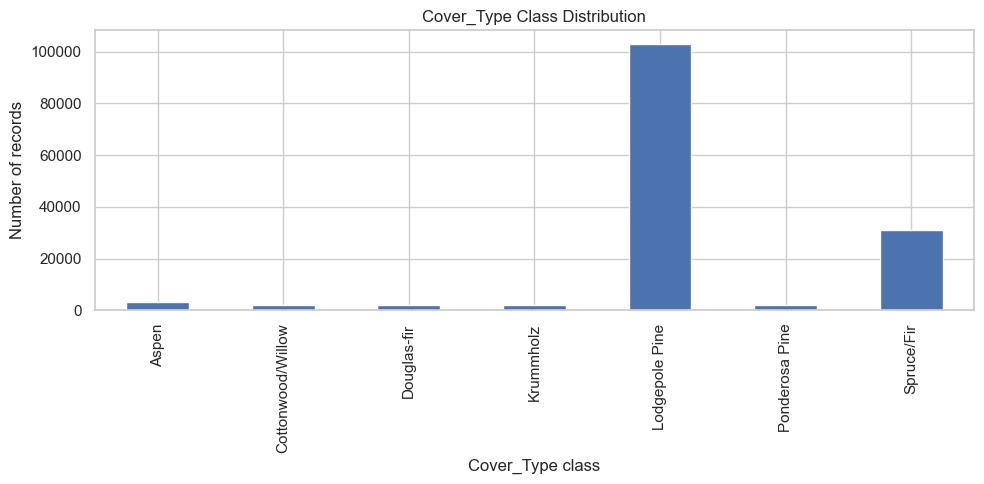

,Count,Percentage
Cover_Type,,
Aspen,3069,2.10
Cottonwood/Willow,2160,1.48
Douglas-fir,2160,1.48
Krummholz,2160,1.48
Lodgepole Pine,103071,70.65
Ponderosa Pine,2160,1.48
Spruce/Fir,31110,21.32


Imbalance ratio (largest / smallest class): 47.72:1


In [4]:
class_counts = df[TARGET].value_counts().sort_index()
imbalance_ratio = class_counts.max() / class_counts.min()

fig, ax = plt.subplots(figsize=(10, 5))
class_counts.plot(kind="bar", ax=ax)
ax.set_title("Cover_Type Class Distribution")
ax.set_xlabel("Cover_Type class")
ax.set_ylabel("Number of records")
plt.tight_layout()
plt.show()

display(pd.DataFrame({
    "Count": class_counts,
    "Percentage": (class_counts / len(df) * 100).round(2)
}))
print(f"Imbalance ratio (largest / smallest class): {imbalance_ratio:.2f}:1")


## 4. Data cleaning — duplicates and missing values
Do not silently remove duplicate rows until you understand whether they are repeated observations or valid identical feature combinations. Missing values will be imputed inside model pipelines: median for numeric features and most frequent category for categorical features.

In [5]:
duplicate_count = int(df.duplicated().sum())
missing_summary = df.isna().sum()

print("Duplicate rows requiring investigation:", duplicate_count)
display(missing_summary[missing_summary > 0].to_frame("Missing_Count"))

# Remove exact duplicate rows only if they are confirmed accidental duplicates.
# The dataset is retained here by default; document any decision to remove them.
df_clean = df.copy()
print("Rows retained for modeling:", len(df_clean))


Duplicate rows requiring investigation: 0


,Missing_Count


Rows retained for modeling: 145890


## 5. EDA — univariate distributions, skewness and boxplots
The guide explicitly asks for histograms, boxplots, skewness treatment and heatmaps. Negative `Vertical_Distance_To_Hydrology` values are valid according to the project guide, so this feature must not be treated as invalid merely because it is negative.

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
Elevation,145890.0,2874.458949,210.801279,1863.0,2194.0,2537.0,2747.0,2909.0,3004.0,3182.0,3339.0,3849.0
Aspect,145890.0,141.127418,107.719296,0.0,0.0,12.0,54.0,108.0,217.0,344.0,356.0,360.0
Slope,145890.0,11.925574,6.319326,0.0,1.0,3.0,7.0,11.0,15.0,24.0,31.0,61.0
Horizontal_Distance_To_Hydrology,145890.0,251.824738,192.473899,0.0,0.0,30.0,95.0,212.0,362.0,618.0,824.0,1343.0
Vertical_Distance_To_Hydrology,145890.0,34.554322,41.215776,-146.0,-28.0,-5.0,7.0,23.0,51.0,115.0,184.0,554.0
Horizontal_Distance_To_Roadways,145890.0,3313.827541,1687.779953,0.0,256.0,624.0,1848.0,3420.0,4673.0,5886.0,6468.0,7117.0
Hillshade_9am,145890.0,217.368106,21.590298,0.0,145.0,176.0,207.0,222.0,232.0,244.0,251.0,254.0
Hillshade_Noon,145890.0,224.874748,16.084851,99.0,176.0,196.0,216.0,226.0,236.0,248.0,252.0,254.0
Hillshade_3pm,145890.0,139.788203,31.311690,0.0,58.0,89.0,121.0,140.0,159.0,192.0,213.0,248.0
Horizontal_Distance_To_Fire_Points,145890.0,3044.958105,1761.882341,0.0,242.0,573.0,1608.0,2713.0,4478.0,6170.0,6576.0,7173.0


,Skewness
Vertical_Distance_To_Hydrology,1.792939
Hillshade_9am,-1.286839
Horizontal_Distance_To_Hydrology,0.984953
Hillshade_Noon,-0.945446
Slope,0.943937
Aspect,0.689432
Elevation,-0.664497
Horizontal_Distance_To_Fire_Points,0.365249
Hillshade_3pm,-0.165213
Horizontal_Distance_To_Roadways,-0.058240


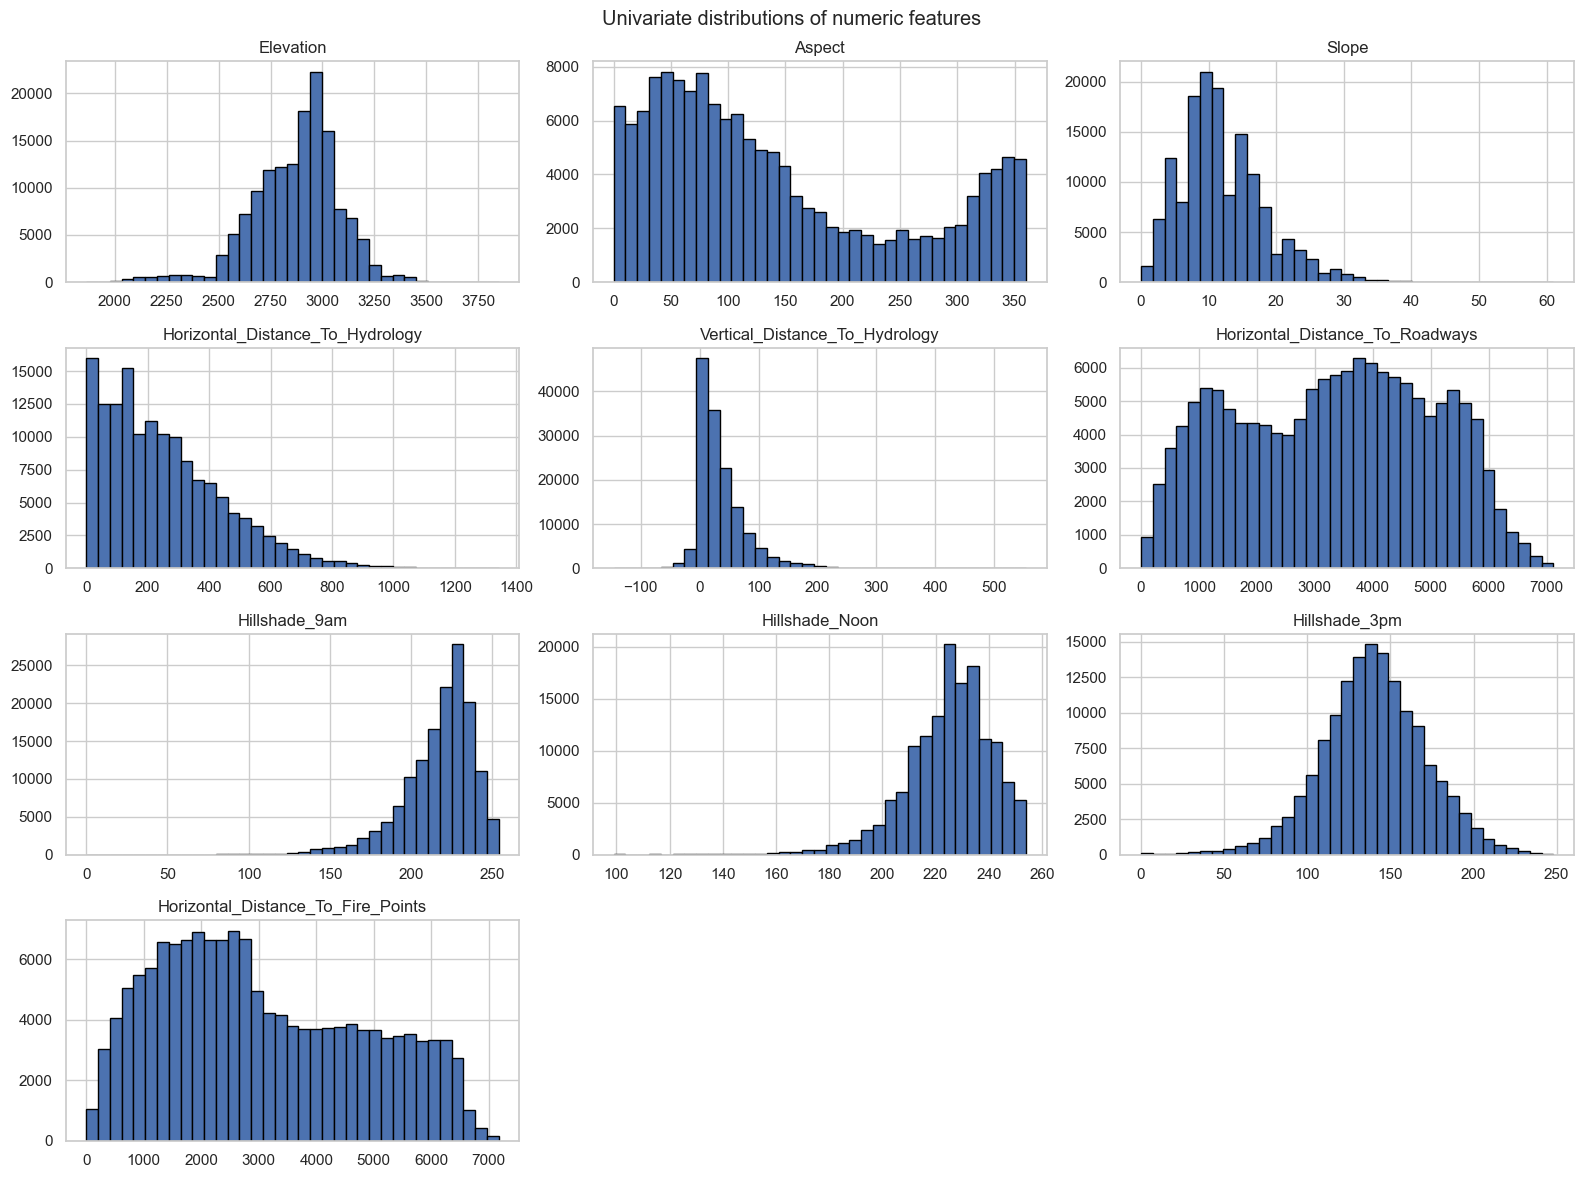

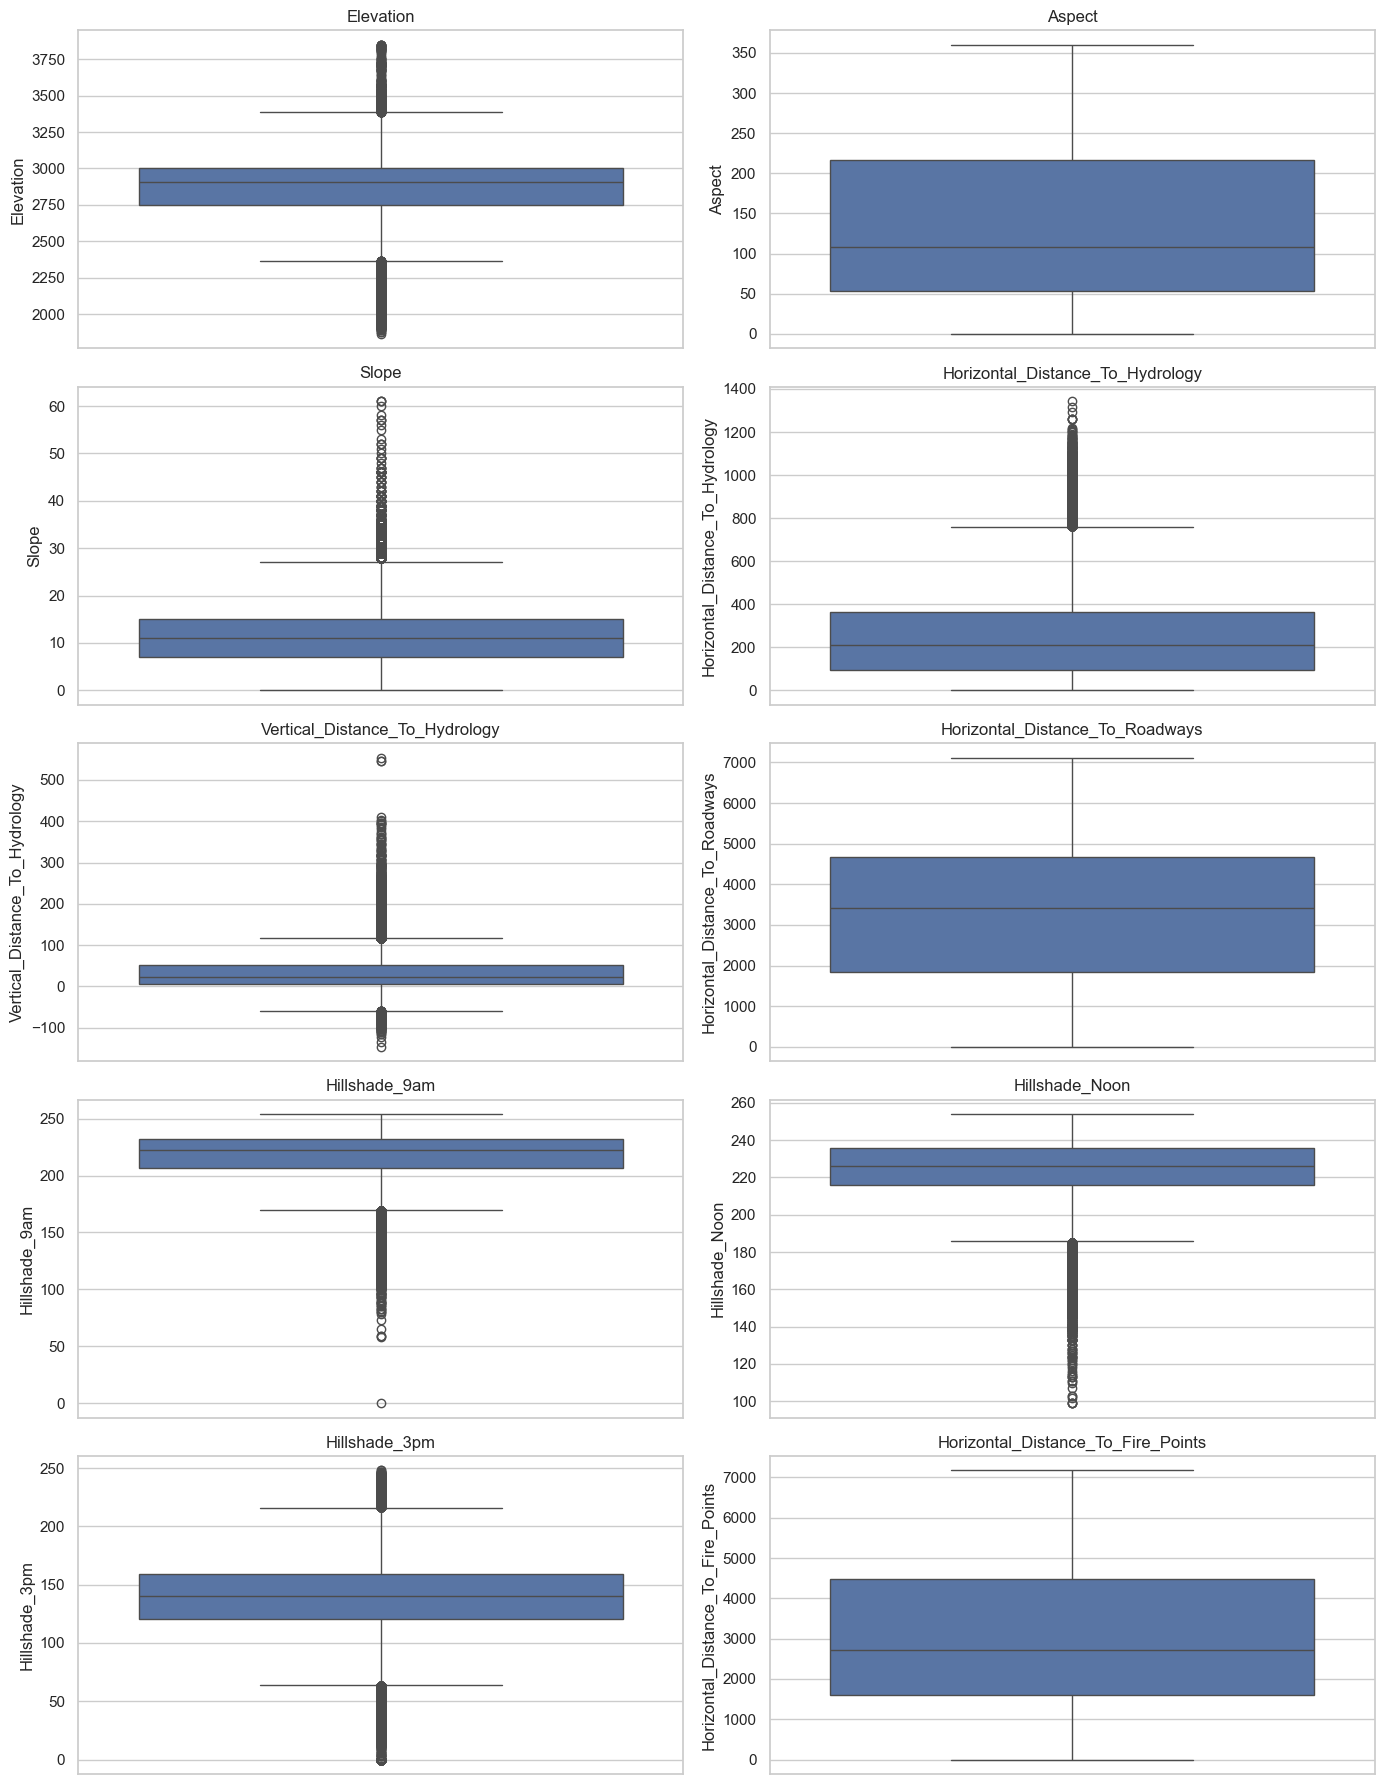

In [6]:
NUMERIC_FEATURES = [
    "Elevation", "Aspect", "Slope",
    "Horizontal_Distance_To_Hydrology",
    "Vertical_Distance_To_Hydrology",
    "Horizontal_Distance_To_Roadways",
    "Hillshade_9am", "Hillshade_Noon", "Hillshade_3pm",
    "Horizontal_Distance_To_Fire_Points"
]
CATEGORICAL_FEATURES = ["Wilderness_Area", "Soil_Type"]

display(df_clean[NUMERIC_FEATURES].describe(
    percentiles=[.01, .05, .25, .50, .75, .95, .99]
).T)

skewness_report = df_clean[NUMERIC_FEATURES].skew().sort_values(
    key=lambda s: s.abs(), ascending=False
).to_frame("Skewness")
display(skewness_report)

df_clean[NUMERIC_FEATURES].hist(figsize=(16, 12), bins=35, edgecolor="black")
plt.suptitle("Univariate distributions of numeric features")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(5, 2, figsize=(14, 18))
for feature, ax in zip(NUMERIC_FEATURES, axes.ravel()):
    sns.boxplot(y=df_clean[feature], ax=ax)
    ax.set_title(feature)
plt.tight_layout()
plt.show()


## 6. Outlier detection and handling
### Step 6A — detect IQR outliers
IQR flags values outside Q1 − 1.5×IQR and Q3 + 1.5×IQR. These are statistical flags, not proof of incorrect records.

In [7]:
iqr_rows = []
for feature in NUMERIC_FEATURES:
    q1 = df_clean[feature].quantile(0.25)
    q3 = df_clean[feature].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    flags = (df_clean[feature] < lower) | (df_clean[feature] > upper)
    iqr_rows.append({
        "Feature": feature,
        "Lower_Bound": lower,
        "Upper_Bound": upper,
        "Flagged_Count": int(flags.sum()),
        "Flagged_Percent": round(flags.mean() * 100, 2)
    })

iqr_report = pd.DataFrame(iqr_rows).sort_values("Flagged_Percent", ascending=False)
display(iqr_report)


,Feature,Lower_Bound,Upper_Bound,Flagged_Count,Flagged_Percent
4,Vertical_Distance_To_Hydrology,-59.0,117.0,7123,4.88
6,Hillshade_9am,169.5,269.5,5242,3.59
0,Elevation,2361.5,3389.5,4448,3.05
2,Slope,-5.0,27.0,3385,2.32
7,Hillshade_Noon,186.0,266.0,3211,2.20
8,Hillshade_3pm,64.0,216.0,3087,2.12
3,Horizontal_Distance_To_Hydrology,-305.5,762.5,2473,1.70
1,Aspect,-190.5,461.5,0,0.00
5,Horizontal_Distance_To_Roadways,-2389.5,8910.5,0,0.00
9,Horizontal_Distance_To_Fire_Points,-2697.0,8783.0,0,0.00


### Step 6B — domain validation
The project guide documents Aspect as 0–360, Slope as degrees, hillshade as 0–255, and vertical hydrology distance as potentially negative. Review violations before changing data.

In [8]:
domain_rules = {
    "Elevation": (0, None),
    "Aspect": (0, 360),
    "Slope": (0, 90),
    "Horizontal_Distance_To_Hydrology": (0, None),
    "Vertical_Distance_To_Hydrology": (None, None),  # negative values are valid
    "Horizontal_Distance_To_Roadways": (0, None),
    "Hillshade_9am": (0, 255),
    "Hillshade_Noon": (0, 255),
    "Hillshade_3pm": (0, 255),
    "Horizontal_Distance_To_Fire_Points": (0, None),
}
domain_rows = []
for feature, (lower, upper) in domain_rules.items():
    bad = pd.Series(False, index=df_clean.index)
    if lower is not None:
        bad |= df_clean[feature] < lower
    if upper is not None:
        bad |= df_clean[feature] > upper
    domain_rows.append({"Feature": feature, "Domain_Violations": int(bad.sum())})

domain_report = pd.DataFrame(domain_rows)
display(domain_report)


,Feature,Domain_Violations
0,Elevation,0
1,Aspect,0
2,Slope,0
3,Horizontal_Distance_To_Hydrology,0
4,Vertical_Distance_To_Hydrology,0
5,Horizontal_Distance_To_Roadways,0
6,Hillshade_9am,0
7,Hillshade_Noon,0
8,Hillshade_3pm,0
9,Horizontal_Distance_To_Fire_Points,0


### Step 6C — split first, then fit outlier caps on training data only
This experiment uses training-set IQR limits to cap extreme values in numeric columns. It does **not** remove records. Compare raw versus capped data later. Keep the raw version if capping reduces validation performance or removes meaningful variation.

In [9]:
X = df_clean[FEATURES].copy()
y = df_clean[TARGET].copy()

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

def fit_iqr_caps(train_frame, columns):
    caps = {}
    for feature in columns:
        q1 = train_frame[feature].quantile(0.25)
        q3 = train_frame[feature].quantile(0.75)
        iqr = q3 - q1
        caps[feature] = (q1 - 1.5 * iqr, q3 + 1.5 * iqr)
    return caps

def apply_caps(frame, caps):
    result = frame.copy()
    for feature, (lower, upper) in caps.items():
        result[feature] = result[feature].clip(lower=lower, upper=upper)
    return result

iqr_caps = fit_iqr_caps(X_train_raw, NUMERIC_FEATURES)
X_train_capped = apply_caps(X_train_raw, iqr_caps)
X_test_capped = apply_caps(X_test_raw, iqr_caps)

print("Training rows:", len(X_train_raw), "Testing rows:", len(X_test_raw))
print("Capping limits learned from training data only.")


Training rows: 116712 Testing rows: 29178
Capping limits learned from training data only.


## 7. Skewness treatment — train-only log1p experiment
The guide suggests `log1p` for skewed continuous variables. Apply it only to non-negative features whose absolute training skewness exceeds the selected threshold. Do not apply `log1p` to vertical hydrology distance because it can be negative. The same selected columns are transformed in test data.

In [10]:
skewness_train = X_train_capped[NUMERIC_FEATURES].skew()
LOG_FEATURES = [
    feature for feature in NUMERIC_FEATURES
    if skewness_train[feature] > 1.0
    and (X_train_capped[feature] >= 0).all()
]
print("Features selected for log1p based on training skewness:", LOG_FEATURES)

def apply_log1p(frame, columns):
    result = frame.copy()
    for feature in columns:
        result[feature] = np.log1p(result[feature].clip(lower=0))
    return result

X_train_prepared = apply_log1p(X_train_capped, LOG_FEATURES)
X_test_prepared = apply_log1p(X_test_capped, LOG_FEATURES)

print("Prepared training data shape:", X_train_prepared.shape)


Features selected for log1p based on training skewness: []
Prepared training data shape: (116712, 12)


## 8. Feature engineering — terrain-aware derived features
The guide suggests interaction terms, distance ratios and hillshade differences. We create a small interpretable set and retain the original features. The new features are candidates and must be validated experimentally.

In [11]:
def engineer_forest_features(frame):
    result = frame.copy()

    # Aspect is circular: 359 degrees is close to 1 degree.
    aspect_radians = np.deg2rad(result["Aspect"] % 360)
    result["Aspect_Sin"] = np.sin(aspect_radians)
    result["Aspect_Cos"] = np.cos(aspect_radians)

    # Straight-line 3D distance to hydrology.
    result["Hydrology_Distance_3D"] = np.sqrt(
        result["Horizontal_Distance_To_Hydrology"] ** 2
        + result["Vertical_Distance_To_Hydrology"] ** 2
    )

    # Relative vertical displacement; denominator is protected from zero.
    result["Hydrology_Vertical_Ratio"] = (
        result["Vertical_Distance_To_Hydrology"]
        / (result["Horizontal_Distance_To_Hydrology"] + 1.0)
    )

    # Illumination summary and time-of-day differences.
    shades = ["Hillshade_9am", "Hillshade_Noon", "Hillshade_3pm"]
    result["Hillshade_Mean"] = result[shades].mean(axis=1)
    result["Hillshade_Range"] = result[shades].max(axis=1) - result[shades].min(axis=1)
    result["Hillshade_Morning_Evening_Diff"] = (
        result["Hillshade_9am"] - result["Hillshade_3pm"]
    )
    result["Hillshade_Noon_Morning_Diff"] = (
        result["Hillshade_Noon"] - result["Hillshade_9am"]
    )

    return result

X_train_eng = engineer_forest_features(X_train_prepared)
X_test_eng = engineer_forest_features(X_test_prepared)

ENGINEERED_FEATURES = list(X_train_eng.columns)
print("Original feature count:", len(FEATURES))
print("After feature engineering:", len(ENGINEERED_FEATURES))
display(X_train_eng.head())


Original feature count: 12
After feature engineering: 20


,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,Wilderness_Area,Soil_Type,Aspect_Sin,Aspect_Cos,Hydrology_Distance_3D,Hydrology_Vertical_Ratio,Hillshade_Mean,Hillshade_Range,Hillshade_Morning_Evening_Diff,Hillshade_Noon_Morning_Diff
48006,2995.0,152,10,600.0,86,5567,233.0,240,137,4056,1,29,0.469472,-0.882948,606.131999,0.143095,203.333333,103.0,96.0,7.0
12365,2361.5,297,27,201.0,117,1410,169.5,214,216,674,4,10,-0.891007,0.453990,232.572569,0.579208,199.833333,46.5,-46.5,44.5
125041,2898.0,103,8,175.0,43,2866,233.0,230,130,2239,1,30,0.974370,-0.224951,180.205438,0.244318,197.666667,103.0,103.0,-3.0
124283,2949.0,125,14,268.0,53,3384,242.0,230,113,1684,1,29,0.819152,-0.573576,273.190410,0.197026,195.000000,129.0,129.0,-12.0
70536,2845.0,142,16,67.0,10,2893,241.0,235,117,2971,1,30,0.615661,-0.788011,67.742158,0.147059,197.666667,124.0,124.0,-6.0


## 9. Bivariate EDA and correlation analysis
The target is categorical, so use class-wise summaries and selected plots rather than interpreting correlation with class numbers as a continuous relationship.

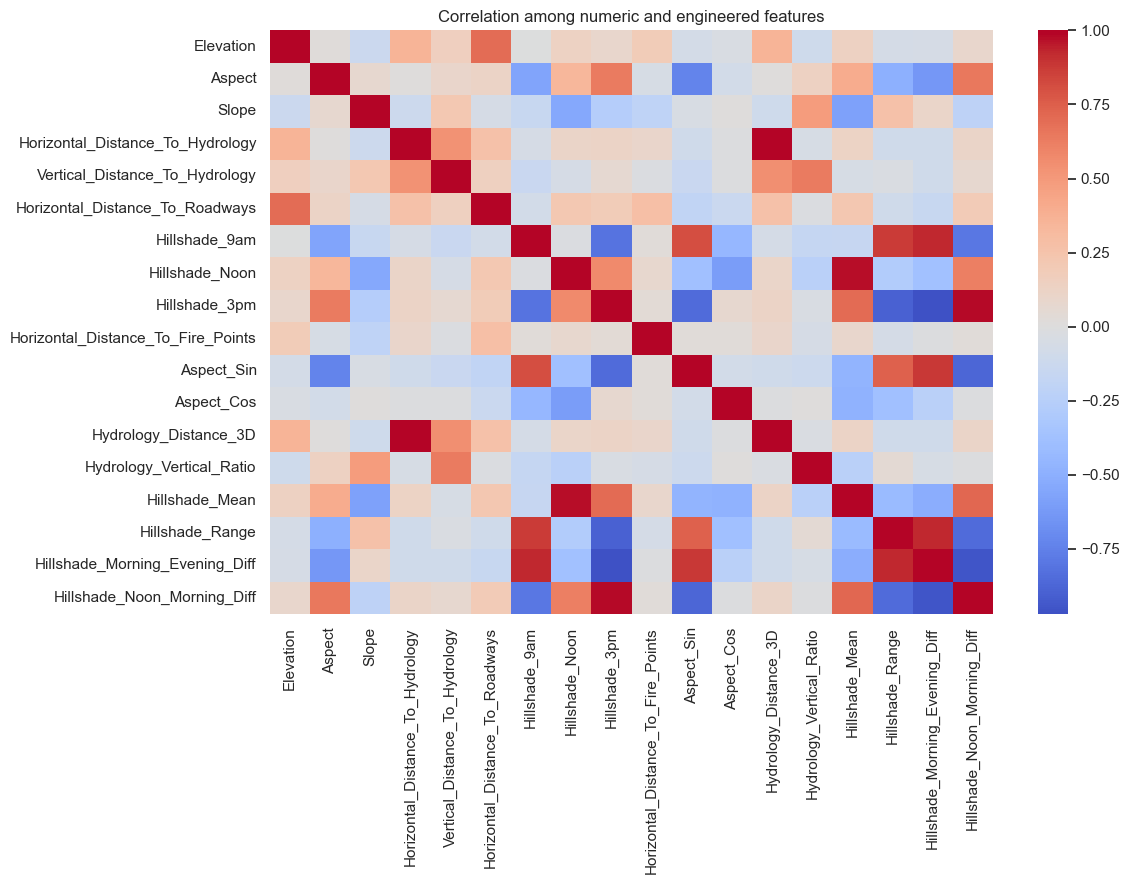

,mean,median,min,max
Cover_Type,,,,
Aspen,2774.377647,2779.0,2482,3007
Cottonwood/Willow,2223.420370,2230.5,1989,2526
Douglas-fir,2423.276852,2430.0,1863,2883
Krummholz,3362.769907,3364.0,2870,3849
Lodgepole Pine,2854.791299,2883.0,2169,3413
Ponderosa Pine,2398.423148,2409.0,1903,2850
Spruce/Fir,3025.169206,3037.0,2518,3675


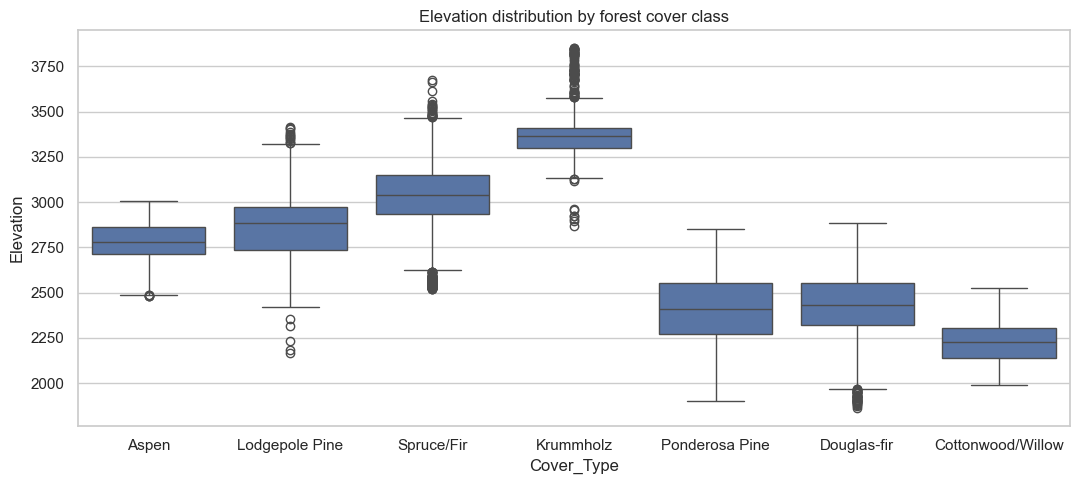

In [12]:
plt.figure(figsize=(12, 9))
sns.heatmap(X_train_eng[NUMERIC_FEATURES + [
    "Aspect_Sin", "Aspect_Cos", "Hydrology_Distance_3D",
    "Hydrology_Vertical_Ratio", "Hillshade_Mean", "Hillshade_Range",
    "Hillshade_Morning_Evening_Diff", "Hillshade_Noon_Morning_Diff"
]].corr(), cmap="coolwarm", center=0)
plt.title("Correlation among numeric and engineered features")
plt.tight_layout()
plt.show()

class_elevation = df_clean.groupby(TARGET)["Elevation"].agg(["mean", "median", "min", "max"])
display(class_elevation)

plt.figure(figsize=(11, 5))
sns.boxplot(data=df_clean, x=TARGET, y="Elevation")
plt.title("Elevation distribution by forest cover class")
plt.tight_layout()
plt.show()


## 10. Preprocessing and categorical encoding
`Wilderness_Area` and `Soil_Type` are categorical identifiers. One-hot encode them, impute numeric missing values with median and categorical missing values with most frequent value. Scale numeric data for Logistic Regression and KNN.

In [13]:
ENGINEERED_NUMERIC = [
    c for c in ENGINEERED_FEATURES
    if c not in CATEGORICAL_FEATURES
]

try:
    ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=True)
except TypeError:
    ohe = OneHotEncoder(handle_unknown="ignore", sparse=True)

numeric_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])
categorical_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", ohe)
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_preprocessor, ENGINEERED_NUMERIC),
    ("categorical", categorical_preprocessor, CATEGORICAL_FEATURES)
])

scaled_preprocessor = ColumnTransformer([
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), ENGINEERED_NUMERIC),
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", ohe)
    ]), CATEGORICAL_FEATURES)
])


## 11. Baseline model — original features, no resampling
Create a baseline before comparing feature engineering and imbalance strategies. The test split remains unchanged.

In [14]:
baseline_preprocessor = ColumnTransformer([
    ("numeric", SimpleImputer(strategy="median"), NUMERIC_FEATURES),
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", ohe)
    ]), CATEGORICAL_FEATURES)
])

baseline_model = Pipeline([
    ("preprocess", baseline_preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=250, random_state=RANDOM_STATE, n_jobs=-1
    ))
])

def evaluate_predictions(name, y_true, y_pred, elapsed=None):
    return {
        "Experiment": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro_F1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "Weighted_F1": f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "Fit_Predict_Seconds": elapsed
    }

t0 = time.time()
baseline_model.fit(X_train_raw, y_train)
baseline_pred = baseline_model.predict(X_test_raw)
baseline_seconds = time.time() - t0

results = [evaluate_predictions(
    "Baseline: original features + Random Forest",
    y_test, baseline_pred, baseline_seconds
)]
display(pd.DataFrame(results).round(4))


,Experiment,Accuracy,Macro_F1,Weighted_F1,Fit_Predict_Seconds
0,Baseline: original features + Random Forest,0.9453,0.9001,0.9443,142.3382


## 12. Outlier treatment experiment — raw versus IQR-capped
This checks whether capping improves or harms a model. Both models use the same split and algorithm. Do not assume capping is better.

In [ ]:
capped_rf = Pipeline([
    ("preprocess", baseline_preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=250, random_state=RANDOM_STATE, n_jobs=-1
    ))
])
t0 = time.time()
capped_rf.fit(X_train_capped, y_train)
capped_pred = capped_rf.predict(X_test_capped)
capped_seconds = time.time() - t0

results.append(evaluate_predictions(
    "IQR-capped original features + Random Forest",
    y_test, capped_pred, capped_seconds
))
display(pd.DataFrame(results).round(4))


## 13. Feature engineering experiment — compare original and engineered features
Both experiments use the same training/test records. Engineered model uses imputation and categorical one-hot encoding.

In [15]:
engineered_rf = Pipeline([
    ("preprocess", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=250, random_state=RANDOM_STATE, n_jobs=-1
    ))
])
t0 = time.time()
engineered_rf.fit(X_train_eng, y_train)
engineered_pred = engineered_rf.predict(X_test_eng)
engineered_seconds = time.time() - t0

results.append(evaluate_predictions(
    "Engineered features + Random Forest",
    y_test, engineered_pred, engineered_seconds
))
display(pd.DataFrame(results).round(4))


,Experiment,Accuracy,Macro_F1,Weighted_F1,Fit_Predict_Seconds
0,Baseline: original features + Random Forest,0.9453,0.9001,0.9443,142.3382
1,Engineered features + Random Forest,0.9302,0.8702,0.9282,21.2062


## 14. Class imbalance handling — required experiments
Compare class weighting, RandomOverSampler and SMOTENC. Resampling is applied only to the training split. For SMOTENC, the two category columns remain categorical until after resampling; one-hot encoding is then applied by the model pipeline.

In [16]:
# A. Class weighting
weighted_rf = Pipeline([
    ("preprocess", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=250, class_weight="balanced",
        random_state=RANDOM_STATE, n_jobs=-1
    ))
])
t0 = time.time()
weighted_rf.fit(X_train_eng, y_train)
weighted_pred = weighted_rf.predict(X_test_eng)
weighted_seconds = time.time() - t0
results.append(evaluate_predictions(
    "Engineered + class_weight Random Forest",
    y_test, weighted_pred, weighted_seconds
))

# B. RandomOverSampler: duplicate minority samples in training data only.
ros = RandomOverSampler(random_state=RANDOM_STATE)
X_ros, y_ros = ros.fit_resample(X_train_eng, y_train)

ros_rf = Pipeline([
    ("preprocess", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=250, random_state=RANDOM_STATE, n_jobs=-1
    ))
])
t0 = time.time()
ros_rf.fit(X_ros, y_ros)
ros_pred = ros_rf.predict(X_test_eng)
ros_seconds = time.time() - t0
results.append(evaluate_predictions(
    "Engineered + RandomOverSampler Random Forest",
    y_test, ros_pred, ros_seconds
))

print("Training rows before ROS:", len(X_train_eng))
print("Training rows after ROS:", len(X_ros))


Training rows before ROS: 116712
Training rows after ROS: 577199


## 15. SMOTENC — synthetic mixed-type oversampling
SMOTENC handles numeric and categorical inputs together. It must be applied before one-hot encoding. This may be computationally expensive; the sample size is not reduced.

In [17]:
cat_indices = [X_train_eng.columns.get_loc(c) for c in CATEGORICAL_FEATURES]

smotenc = SMOTENC(
    categorical_features=cat_indices,
    sampling_strategy="not majority",
    k_neighbors=5,
    random_state=RANDOM_STATE
)
X_smote, y_smote = smotenc.fit_resample(X_train_eng, y_train)

smotenc_rf = Pipeline([
    ("preprocess", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=250, random_state=RANDOM_STATE, n_jobs=-1
    ))
])
t0 = time.time()
smotenc_rf.fit(X_smote, y_smote)
smotenc_pred = smotenc_rf.predict(X_test_eng)
smotenc_seconds = time.time() - t0

results.append(evaluate_predictions(
    "Engineered + SMOTENC Random Forest",
    y_test, smotenc_pred, smotenc_seconds
))
print("Training rows before SMOTENC:", len(X_train_eng))
print("Training rows after SMOTENC:", len(X_smote))


Training rows before SMOTENC: 116712
Training rows after SMOTENC: 577199


## 16. Compare data treatment and imbalance experiments
Choose the approach using Macro F1, class-wise recall and accuracy together. A high accuracy score alone may hide poor performance on minority classes.

In [18]:
experiment_comparison = pd.DataFrame(results).sort_values(
    ["Macro_F1", "Accuracy"], ascending=False
)
display(experiment_comparison.round(4))


,Experiment,Accuracy,Macro_F1,Weighted_F1,Fit_Predict_Seconds
0,Baseline: original features + Random Forest,0.9453,0.9001,0.9443,142.3382
4,Engineered + SMOTENC Random Forest,0.9409,0.8931,0.9411,176.4441
3,Engineered + RandomOverSampler Random Forest,0.9387,0.8849,0.9380,154.7386
1,Engineered features + Random Forest,0.9302,0.8702,0.9282,21.2062
2,Engineered + class_weight Random Forest,0.9285,0.8696,0.9264,45.6243


## 17. Feature importance and actual feature selection
Use a Random Forest fitted on training data to rank features. Select a top-k set using training data only, then compare the selected-feature model on the held-out test set. This is an experiment; retain all features if selection reduces performance.

,Feature,Importance
0,numeric__Elevation,0.188262
5,numeric__Horizontal_Distance_To_Roadways,0.096784
9,numeric__Horizontal_Distance_To_Fire_Points,0.072434
18,categorical__Wilderness_Area_1,0.051062
21,categorical__Wilderness_Area_4,0.043588
12,numeric__Hydrology_Distance_3D,0.040930
3,numeric__Horizontal_Distance_To_Hydrology,0.036117
4,numeric__Vertical_Distance_To_Hydrology,0.030744
13,numeric__Hydrology_Vertical_Ratio,0.030540
20,categorical__Wilderness_Area_3,0.029714


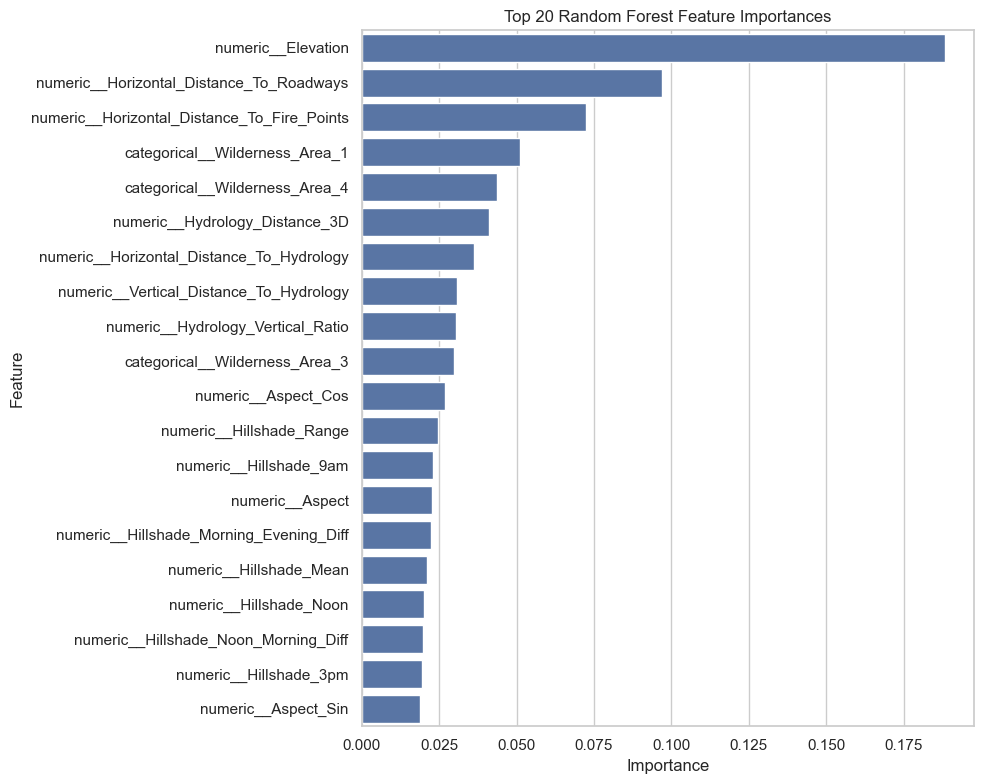

,Experiment,Accuracy,Macro_F1,Weighted_F1,Fit_Predict_Seconds
0,Baseline: original features + Random Forest,0.9453,0.9001,0.9443,142.3382
4,Engineered + SMOTENC Random Forest,0.9409,0.8931,0.9411,176.4441
3,Engineered + RandomOverSampler Random Forest,0.9387,0.8849,0.9380,154.7386
5,Top 30 encoded features + Random Forest,0.9377,0.8746,0.9363,18.4415
1,Engineered features + Random Forest,0.9302,0.8702,0.9282,21.2062
2,Engineered + class_weight Random Forest,0.9285,0.8696,0.9264,45.6243


In [19]:
# Fit preprocessing on training data and obtain readable encoded feature names.
preprocessor_for_importance = preprocessor.fit(X_train_eng, y_train)
X_train_encoded = preprocessor_for_importance.transform(X_train_eng)

try:
    encoded_names = preprocessor_for_importance.get_feature_names_out()
except Exception:
    encoded_names = [f"encoded_feature_{i}" for i in range(X_train_encoded.shape[1])]

importance_rf = RandomForestClassifier(
    n_estimators=250, class_weight="balanced",
    random_state=RANDOM_STATE, n_jobs=-1
)
importance_rf.fit(X_train_encoded, y_train)

importance_table = pd.DataFrame({
    "Feature": encoded_names,
    "Importance": importance_rf.feature_importances_
}).sort_values("Importance", ascending=False)

display(importance_table.head(25))
plt.figure(figsize=(10, 8))
sns.barplot(data=importance_table.head(20), x="Importance", y="Feature")
plt.title("Top 20 Random Forest Feature Importances")
plt.tight_layout()
plt.show()

TOP_K = min(30, X_train_encoded.shape[1])
selected_encoded_features = importance_table.head(TOP_K)["Feature"].tolist()
selected_indices = [list(encoded_names).index(name) for name in selected_encoded_features]

X_test_encoded = preprocessor_for_importance.transform(X_test_eng)
X_train_selected = X_train_encoded[:, selected_indices]
X_test_selected = X_test_encoded[:, selected_indices]

selection_rf = RandomForestClassifier(
    n_estimators=250, class_weight="balanced",
    random_state=RANDOM_STATE, n_jobs=-1
)
t0 = time.time()
selection_rf.fit(X_train_selected, y_train)
selection_pred = selection_rf.predict(X_test_selected)
selection_seconds = time.time() - t0

results.append(evaluate_predictions(
    f"Top {TOP_K} encoded features + Random Forest",
    y_test, selection_pred, selection_seconds
))
display(pd.DataFrame(results).sort_values(
    ["Macro_F1", "Accuracy"], ascending=False
).round(4))


## 18. Five required classification algorithms
The GUVI/HCL guide explicitly names **Random Forest, Decision Tree, Logistic Regression, KNN and XGBoost**. This section uses exactly those five. Numeric features are scaled for Logistic Regression and KNN. All algorithms use the engineered dataset and the same split for comparison.

In [20]:
if not XGBOOST_AVAILABLE:
    raise ImportError("The project guide requires XGBoost. Install it with: pip install xgboost")

models = {
    "Random Forest": Pipeline([
        ("preprocess", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=250, class_weight="balanced",
            random_state=RANDOM_STATE, n_jobs=-1
        ))
    ]),
    "Decision Tree": Pipeline([
        ("preprocess", preprocessor),
        ("classifier", DecisionTreeClassifier(
            class_weight="balanced", random_state=RANDOM_STATE,
            max_depth=None
        ))
    ]),
    "Logistic Regression": Pipeline([
        ("preprocess", scaled_preprocessor),
        ("classifier", LogisticRegression(
            max_iter=2000, class_weight="balanced",
            random_state=RANDOM_STATE
        ))
    ]),
    "K-Nearest Neighbors": Pipeline([
        ("preprocess", scaled_preprocessor),
        ("classifier", KNeighborsClassifier(
            n_neighbors=7, weights="distance", n_jobs=-1
        ))
    ]),
    "XGBoost": Pipeline([
        ("preprocess", preprocessor),
        ("classifier", XGBClassifier(
            n_estimators=250,
            max_depth=8,
            learning_rate=0.1,
            subsample=0.9,
            colsample_bytree=0.9,
            objective="multi:softprob",
            eval_metric="mlogloss",
            tree_method="hist",
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ])
}

from sklearn.preprocessing import LabelEncoder

model_rows = []
fitted_models = {}
xgb_target_encoder = LabelEncoder()

for model_name, model_pipeline in models.items():
    print(f"Training: {model_name}")
    start = time.time()

    if model_name == "XGBoost":
        # XGBoost multiclass labels must be encoded contiguously from 0.
        y_train_xgb = xgb_target_encoder.fit_transform(y_train)
        model_pipeline.fit(X_train_eng, y_train_xgb)
        encoded_predictions = model_pipeline.predict(X_test_eng).astype(int)
        predictions = xgb_target_encoder.inverse_transform(encoded_predictions)
    else:
        model_pipeline.fit(X_train_eng, y_train)
        predictions = model_pipeline.predict(X_test_eng)

    elapsed = time.time() - start
    fitted_models[model_name] = model_pipeline
    model_rows.append(evaluate_predictions(
        model_name, y_test, predictions, elapsed
    ))

model_comparison = pd.DataFrame(model_rows).sort_values(
    ["Macro_F1", "Accuracy"], ascending=False
)
display(model_comparison.round(4))


Training: Random Forest
Training: Decision Tree
Training: Logistic Regression
Training: K-Nearest Neighbors
Training: XGBoost


,Experiment,Accuracy,Macro_F1,Weighted_F1,Fit_Predict_Seconds
4,XGBoost,0.9508,0.9028,0.9503,37.3983
0,Random Forest,0.9285,0.8696,0.9264,23.9940
1,Decision Tree,0.9345,0.8409,0.9343,5.2601
3,K-Nearest Neighbors,0.8976,0.8019,0.8954,6.6520
2,Logistic Regression,0.6709,0.6506,0.7051,24.6102


## 19. Select the best model and tune it
Choose the best algorithm using the comparison table, with Macro F1 as the primary ranking metric and Accuracy as a secondary metric. This cell tunes Random Forest as a reproducible starting candidate. If another algorithm clearly wins, tune that algorithm separately before final selection.

In [21]:
best_algorithm_name = model_comparison.iloc[0]["Experiment"]
print("Best algorithm from initial comparison:", best_algorithm_name)

# Random Forest tuning is included because it is a strong tree-based baseline
# and supports class_weight. The final model is selected by CV Macro F1.
rf_tuning_pipeline = Pipeline([
    ("preprocess", preprocessor),
    ("classifier", RandomForestClassifier(
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

param_distributions = {
    "classifier__n_estimators": [200, 300, 400],
    "classifier__max_depth": [None, 20, 30, 40],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__min_samples_leaf": [1, 2, 4],
    "classifier__max_features": ["sqrt", 0.8]
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
search = RandomizedSearchCV(
    estimator=rf_tuning_pipeline,
    param_distributions=param_distributions,
    n_iter=12,
    scoring="f1_macro",
    cv=cv,
    n_jobs=1,
    random_state=RANDOM_STATE,
    verbose=1,
    refit=True
)
search.fit(X_train_eng, y_train)

tuned_rf = search.best_estimator_
print("Best cross-validation Macro F1:", round(search.best_score_, 4))
print("Best parameters:")
display(search.best_params_)


Best algorithm from initial comparison: XGBoost
Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best cross-validation Macro F1: 0.8928
Best parameters:


{'classifier__n_estimators': 300,
 'classifier__min_samples_split': 5,
 'classifier__min_samples_leaf': 1,
 'classifier__max_features': 0.8,
 'classifier__max_depth': 30}

## 20. Final model selection and untouched test evaluation
Compare the tuned Random Forest with the five initial models using the same untouched test set. The highest Macro F1 is selected here; inspect accuracy and class-level metrics before finalizing.

In [22]:
final_candidates = dict(fitted_models)
final_candidates["Tuned Random Forest"] = tuned_rf

final_rows = []
final_predictions = {}
for name, candidate in final_candidates.items():
    pred = candidate.predict(X_test_eng)
    if name == "XGBoost":
        pred = xgb_target_encoder.inverse_transform(np.asarray(pred, dtype=int))
    final_predictions[name] = pred
    final_rows.append(evaluate_predictions(name, y_test, pred))

final_comparison = pd.DataFrame(final_rows).sort_values(
    ["Macro_F1", "Accuracy"], ascending=False
)
display(final_comparison.round(4))

FINAL_MODEL_NAME = final_comparison.iloc[0]["Experiment"]
best_model = final_candidates[FINAL_MODEL_NAME]
final_pred = final_predictions[FINAL_MODEL_NAME]

print("Selected final model:", FINAL_MODEL_NAME)
print("Final test accuracy:", round(accuracy_score(y_test, final_pred), 4))
print("Final test Macro F1:", round(f1_score(y_test, final_pred, average="macro", zero_division=0), 4))
print("Final test Weighted F1:", round(f1_score(y_test, final_pred, average="weighted", zero_division=0), 4))


,Experiment,Accuracy,Macro_F1,Weighted_F1,Fit_Predict_Seconds
5,Tuned Random Forest,0.9606,0.9043,0.9606,None
4,XGBoost,0.9508,0.9028,0.9503,None
0,Random Forest,0.9285,0.8696,0.9264,None
1,Decision Tree,0.9345,0.8409,0.9343,None
3,K-Nearest Neighbors,0.8976,0.8019,0.8954,None
2,Logistic Regression,0.6709,0.6506,0.7051,None


Selected final model: Tuned Random Forest
Final test accuracy: 0.9606
Final test Macro F1: 0.9043
Final test Weighted F1: 0.9606


## 21. Confusion matrix and classification report
These are required evaluation outputs. They belong in the notebook/report; the Streamlit prediction screen does not need to display probabilities or confidence.

                   precision    recall  f1-score   support

            Aspen       0.86      0.88      0.87       614
Cottonwood/Willow       0.93      0.95      0.94       432
      Douglas-fir       0.81      0.88      0.84       432
        Krummholz       0.91      0.97      0.93       432
   Lodgepole Pine       0.98      0.98      0.98     20614
   Ponderosa Pine       0.84      0.84      0.84       432
       Spruce/Fir       0.95      0.92      0.93      6222

         accuracy                           0.96     29178
        macro avg       0.89      0.91      0.90     29178
     weighted avg       0.96      0.96      0.96     29178



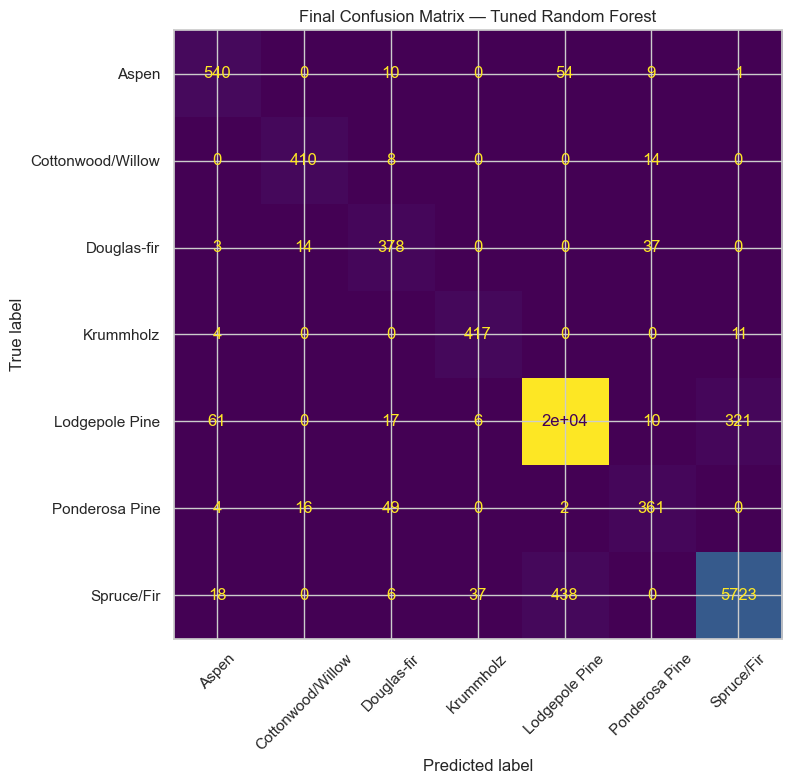

In [23]:
print(classification_report(y_test, final_pred, zero_division=0))

labels = sorted(pd.Series(y).unique())
cm = confusion_matrix(y_test, final_pred, labels=labels)
fig, ax = plt.subplots(figsize=(10, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot(ax=ax, xticks_rotation=45, colorbar=False)
plt.title(f"Final Confusion Matrix — {FINAL_MODEL_NAME}")
plt.tight_layout()
plt.show()


## 22. Per-class metrics
Review precision, recall and F1 for every forest cover class. Minority-class recall is particularly important because the original target distribution is imbalanced.

In [24]:
report_dict = classification_report(
    y_test, final_pred, output_dict=True, zero_division=0
)
report_df = pd.DataFrame(report_dict).T
class_labels = [str(label) for label in labels]
display(report_df.loc[class_labels, [
    "precision", "recall", "f1-score", "support"
]].round(4))


,precision,recall,f1-score,support
Aspen,0.8571,0.8795,0.8682,614.0
Cottonwood/Willow,0.9318,0.9491,0.9404,432.0
Douglas-fir,0.8077,0.8750,0.8400,432.0
Krummholz,0.9065,0.9653,0.9350,432.0
Lodgepole Pine,0.9761,0.9799,0.9780,20614.0
Ponderosa Pine,0.8376,0.8356,0.8366,432.0
Spruce/Fir,0.9450,0.9198,0.9322,6222.0


## 23. Feature importance on the selected final model
Permutation importance estimates how much a metric falls when a feature is shuffled. Run it on a validation set when possible; the held-out test result should remain the final report estimate and should not be repeatedly used to guide feature changes.

In [25]:
# This permutation-importance readout is for interpretation only.
# Do not repeatedly tune the model based on the final test set.
if FINAL_MODEL_NAME in ["Random Forest", "Tuned Random Forest"]:
    final_rf = best_model.named_steps["classifier"]
    final_preprocessor = best_model.named_steps["preprocess"]
    try:
        names = final_preprocessor.get_feature_names_out()
        importances = final_rf.feature_importances_
        final_importance = pd.DataFrame({
            "Feature": names,
            "Importance": importances
        }).sort_values("Importance", ascending=False)
        display(final_importance.head(25))
    except Exception as exc:
        print("Could not retrieve feature importance names:", exc)
else:
    print("The selected algorithm does not expose this tree-based importance view.")


,Feature,Importance
0,numeric__Elevation,0.332629
5,numeric__Horizontal_Distance_To_Roadways,0.109120
18,categorical__Wilderness_Area_1,0.108795
9,numeric__Horizontal_Distance_To_Fire_Points,0.092508
12,numeric__Hydrology_Distance_3D,0.049907
6,numeric__Hillshade_9am,0.030447
11,numeric__Aspect_Cos,0.028846
3,numeric__Horizontal_Distance_To_Hydrology,0.023709
4,numeric__Vertical_Distance_To_Hydrology,0.021739
21,categorical__Wilderness_Area_4,0.020836


## 24. Save the final model and inference metadata as `.pkl`
The project guide explicitly requests a `.pkl` model. Save the **entire fitted preprocessing + classifier pipeline**, not only the classifier. Also save the original input feature list, feature-engineering version, target labels and training-time log-transformation columns for consistent inference.

In [26]:
MODEL_DIR = Path("models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

model_bundle = {
    "model": best_model,
    "model_name": FINAL_MODEL_NAME,
    "input_features": FEATURES,
    "numeric_features": NUMERIC_FEATURES,
    "categorical_features": CATEGORICAL_FEATURES,
    "log1p_features": LOG_FEATURES,
    "feature_engineering_version": "ecotype_terrain_v1",
    "target_name": TARGET,
    "class_labels": list(labels),
    "xgb_target_encoder": xgb_target_encoder if FINAL_MODEL_NAME == "XGBoost" else None,
    "random_state": RANDOM_STATE
}

model_path = MODEL_DIR / "ecotype_best_model.pkl"
joblib.dump(model_bundle, model_path)
print("Final model bundle saved:", model_path.resolve())

# Save a human-readable summary as a second project artifact.
summary = {
    "selected_model": FINAL_MODEL_NAME,
    "test_accuracy": float(accuracy_score(y_test, final_pred)),
    "test_macro_f1": float(f1_score(y_test, final_pred, average="macro", zero_division=0)),
    "test_weighted_f1": float(f1_score(y_test, final_pred, average="weighted", zero_division=0)),
    "input_features": FEATURES,
    "log1p_features": LOG_FEATURES,
    "engineered_features": ENGINEERED_FEATURES
}
with open(MODEL_DIR / "ecotype_model_summary.json", "w", encoding="utf-8") as file:
    json.dump(summary, file, indent=4)
display(summary)


Final model bundle saved: C:\Users\Gokul\OneDrive\Desktop\EcoType_Forest_Cover\notebooks\models\ecotype_best_model.pkl


{'selected_model': 'Tuned Random Forest',
 'test_accuracy': 0.9605867434368359,
 'test_macro_f1': 0.904336967564724,
 'test_weighted_f1': 0.960595197856839,
 'input_features': ['Elevation',
  'Aspect',
  'Slope',
  'Horizontal_Distance_To_Hydrology',
  'Vertical_Distance_To_Hydrology',
  'Horizontal_Distance_To_Roadways',
  'Hillshade_9am',
  'Hillshade_Noon',
  'Hillshade_3pm',
  'Horizontal_Distance_To_Fire_Points',
  'Wilderness_Area',
  'Soil_Type'],
 'log1p_features': [],
 'engineered_features': ['Elevation',
  'Aspect',
  'Slope',
  'Horizontal_Distance_To_Hydrology',
  'Vertical_Distance_To_Hydrology',
  'Horizontal_Distance_To_Roadways',
  'Hillshade_9am',
  'Hillshade_Noon',
  'Hillshade_3pm',
  'Horizontal_Distance_To_Fire_Points',
  'Wilderness_Area',
  'Soil_Type',
  'Aspect_Sin',
  'Aspect_Cos',
  'Hydrology_Distance_3D',
  'Hydrology_Vertical_Ratio',
  'Hillshade_Mean',
  'Hillshade_Range',
  'Hillshade_Morning_Evening_Diff',
  'Hillshade_Noon_Morning_Diff']}

## 25. Test the saved model using a genuine held-out dataset record
The test record is passed through exactly the same transformations used during training. The predicted label is converted to a forest-cover name for display.

In [28]:

loaded_bundle = joblib.load(model_path)
loaded_model = loaded_bundle["model"]

sample_input = X_test_raw.iloc[[0]].copy()
sample_label = y_test.iloc[0]

# Apply the same transformations used during training
sample_capped = apply_caps(sample_input, iqr_caps)
sample_logged = apply_log1p(sample_capped, LOG_FEATURES)
sample_engineered = engineer_forest_features(sample_logged)

# Generate prediction
sample_prediction = loaded_model.predict(sample_engineered)[0]

# Decode XGBoost prediction if required
if loaded_bundle["model_name"] == "XGBoost":
    encoder = loaded_bundle.get("xgb_target_encoder")

    if encoder is not None:
        sample_prediction = encoder.inverse_transform(
            np.asarray([int(sample_prediction)])
        )[0]

COVER_TYPE_NAMES = {
    1: "Spruce/Fir",
    2: "Lodgepole Pine",
    3: "Ponderosa Pine",
    4: "Cottonwood/Willow",
    5: "Aspen",
    6: "Douglas-fir",
    7: "Krummholz"
}

# Handle both numeric labels and already-decoded class names
def get_cover_name(value):
    if isinstance(value, str):
        if value in COVER_TYPE_NAMES.values():
            return value

        try:
            value = int(value)
        except ValueError:
            return value

    return COVER_TYPE_NAMES.get(int(value), str(value))


predicted_name = get_cover_name(sample_prediction)
actual_name = get_cover_name(sample_label)

print("Actual Cover_Type:", sample_label, "-", actual_name)
print("Predicted Cover_Type:", sample_prediction, "-", predicted_name)
print("Correct prediction:", actual_name == predicted_name)


Actual Cover_Type: Spruce/Fir - Spruce/Fir
Predicted Cover_Type: Spruce/Fir - Spruce/Fir
Correct prediction: True


## 26. Streamlit integration contract
The Streamlit application must load `models/ecotype_best_model.pkl`. It must collect all **12 original input fields**, then apply the saved bundle's exact transformations in this order:
1. Build a one-row DataFrame using `input_features`.
2. Apply the training-fitted IQR caps (`iqr_caps`) saved with the bundle.
3. Apply `log1p` to the saved `log1p_features`.
4. Apply the same `engineer_forest_features` transformations.
5. Call `model.predict()` and map the target label to its forest-cover name.

**Important:** the model bundle in this notebook must be updated to include the fitted IQR cap values. Do not let the Streamlit app calculate new caps from user input. The next cell stores those values.

In [29]:
# Update the saved bundle with training-derived outlier cap limits.
model_bundle["iqr_caps"] = {
    feature: [float(bounds[0]), float(bounds[1])]
    for feature, bounds in iqr_caps.items()
}
joblib.dump(model_bundle, model_path)
print("Updated model bundle with train-fitted IQR caps:", model_path.resolve())


Updated model bundle with train-fitted IQR caps: C:\Users\Gokul\OneDrive\Desktop\EcoType_Forest_Cover\notebooks\models\ecotype_best_model.pkl


## 27. Final project checklist against GUVI/HCL guide

| Guide requirement | Notebook section |
|---|---|
| Data collection and understanding | 1–4 |
| Missing values and duplicates | 4, 10 |
| Outlier detection and treatment | 6, 12 |
| Skewness and log transformation | 5, 7 |
| Feature engineering and encoding | 8, 10 |
| Univariate and bivariate EDA | 5, 9 |
| Class imbalance handling | 3, 14–16 |
| Feature importance and selection | 17, 23 |
| Five required algorithms | 18 |
| Accuracy, confusion matrix, classification report | 20–22 |
| Hyperparameter tuning | 19 |
| Save final model as `.pkl` | 24 |
| Streamlit prediction preparation | 25–26 |

### Before submission
- Run every cell from top to bottom without errors.
- Confirm XGBoost is installed and the five required algorithms all train.
- Inspect outlier and skewness reports; do not claim that all outliers were errors.
- Compare raw and capped results; document the selected treatment.
- Confirm the selected model's test metrics and class-wise report.
- Confirm the saved `.pkl` reloads and predicts a genuine held-out record.
- Make `app.py` use this exact model bundle and exact preprocessing steps.
- Keep model evaluation metrics in the notebook/report. The Streamlit UI only needs the predicted class, as required by the guide.

**This notebook implements the required workflow, but actual compliance and model quality are confirmed only after running it successfully on your dataset and validating the outputs.**
